# 05: Compare the trends with daily coverage counts

**DATA 5500, Senior Design**
**Sara Choque Molina**

Notebooks 02 to 04 worked on the text of single articles. This notebook steps back and looks at how many articles appeared each day, which is enough to compare whole trends with each other without reading any of them.

It answers three questions from the project plan:

- **Question 3.** How did each trend start, peak and fade?
- **Question 4.** Are the trends lasting longer over time?
- **Question 5.** Does a viral panic that involved no threats (Momo, 2019) stay quiet under the same measurement?

Four periods are compared. Three are viral school-threat trends, and one is a control:

| Case | Period | What happened |
|---|---|---|
| 2016 Killer Clown | Sep 1 to Nov 14, 2016 | Clown sightings and clown threats against schools spread on social media |
| 2021 TikTok | Nov 15, 2021 to Jan 14, 2022 | A TikTok post warned of shootings at schools across the country on December 17 |
| 2026 Cat in the Hat | Aug 1 to Sep 19, 2026 | A threat trend at the start of the school year |
| 2019 Momo (control) | Feb 1 to Mar 31, 2019 | A viral panic about a "challenge" aimed at children, with no threats against schools |

All counts come from the GDELT 2.0 Global Knowledge Graph in BigQuery. An article is counted when its web address contains "school" together with "threat" or "lockdown".

| File | Contents |
|---|---|
| `09_daily_total_2016_clowns.csv` | Articles per day, 2016 case |
| `12_daily_total_2021_tiktok.csv` | Articles per day, 2021 case |
| `13_daily_total_2026_cathat.csv` | Articles per day, 2026 case |
| `10_daily_total_2019_momo.csv` | Articles per day, Momo control |
| `15_daily_baseline_notrend.csv` | Articles per day for the same weeks of the year in years with no known viral trend |
| `03`, `05`, `06` and `16_daily_categories_*.csv` | Articles per day for each case, split by keyword category |

Figures are saved to the `figures` folder.

## Block 1: Load the daily counts

**This block handles the input.** Before comparing anything, every case has to be on the same footing: one row per calendar day, with no days missing.

BigQuery leaves out a day that had no articles instead of writing a zero. A missing day would make a quiet stretch look shorter than it was, so the calendar is filled back in.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FOLDER = r"C:\Users\sara_\Desktop\College\DATA 5500-01 Senior Des\data bases"

FIGURES = os.path.join(FOLDER, "figures")
os.makedirs(FIGURES, exist_ok=True)

CASES = {
    "2016 Killer Clown": "09_daily_total_2016_clowns.csv",
    "2021 TikTok": "12_daily_total_2021_tiktok.csv",
    "2026 Cat in the Hat": "13_daily_total_2026_cathat.csv",
    "2019 Momo (control)": "10_daily_total_2019_momo.csv",
}


def fill_calendar(df, start, end):
    """Return the counts for every day from start to end, with zero on the missing days."""
    full = pd.date_range(start, end, freq="D")
    df = df.set_index("day").reindex(full, fill_value=0)
    df.index.name = "day"
    return df.reset_index()


def load_daily(filename):
    """Read one daily count file and return it on a day by day calendar."""
    df = pd.read_csv(os.path.join(FOLDER, filename))

    # BigQuery writes the day as a number like 20211217. Without this it would sort
    # as text and the x axis would space the days unevenly.
    df["day"] = pd.to_datetime(df["day"].astype(str), format="%Y%m%d")

    filled = fill_calendar(df, df["day"].min(), df["day"].max())
    filled.attrs["days added"] = len(filled) - len(df)
    return filled


daily = {name: load_daily(f) for name, f in CASES.items()}

pd.DataFrame([
    {
        "case": name,
        "first day": df["day"].min().date(),
        "last day": df["day"].max().date(),
        "days": len(df),
        "empty days filled in": df.attrs["days added"],
        "articles": df["articles"].sum(),
    }
    for name, df in daily.items()
])

,case,first day,last day,days,empty days filled in,articles
0,2016 Killer Clown,2016-09-01,2016-11-14,75,0,6392
1,2021 TikTok,2021-11-15,2022-01-14,61,0,4995
2,2026 Cat in the Hat,2026-08-01,2026-09-19,50,1,1354
3,2019 Momo (control),2019-02-01,2019-03-31,59,0,4264


**What we see**

- Every case is complete from its first day to its last.
- Only the 2026 case had a day with no coverage, and it is now counted as zero.
- The 2016 and 2021 totals, 6,392 and 4,995, match the number of article links exported for those years in notebook 02, so the daily counts and the article files describe the same coverage.

## Block 2: Set the normal level for each case

**This block handles the comparison point.** A raw count cannot be compared across years, because GDELT monitors many more news outlets in 2026 than it did in 2016, and because coverage of schools always rises and falls with the school calendar.

So each case is compared with itself in an ordinary year: the same weeks of the year, in two years with no known viral trend. The question this block answers is: **What does an ordinary day of school-threat coverage look like at that time of year?**

The median is used instead of the mean. The comparison years contain real threat waves of their own, such as the one after the Apalachee High School shooting in September 2024, and a single day of several hundred articles would pull a mean far upward. The median describes the typical day.

In [2]:
BASELINE_FILE = "15_daily_baseline_notrend.csv"

BASELINE_WINDOWS = {
    "2016 Killer Clown":   [("2017-09-01", "2017-11-14"), ("2018-09-01", "2018-11-14")],
    "2021 TikTok":         [("2018-11-15", "2019-01-14"), ("2022-11-15", "2023-01-14")],
    "2026 Cat in the Hat": [("2024-08-01", "2024-09-19"), ("2025-08-01", "2025-09-19")],
    "2019 Momo (control)": [("2017-02-01", "2017-03-31"), ("2018-02-01", "2018-03-31")],
}

baseline = pd.read_csv(os.path.join(FOLDER, BASELINE_FILE))
baseline["day"] = pd.to_datetime(baseline["day"].astype(str), format="%Y%m%d")

# The baseline file holds several separate windows, so each window is filled in on
# its own. Filling the whole file at once would invent years of empty days between
# the windows.
normal = {}
rows = []
for name, windows in BASELINE_WINDOWS.items():
    days = pd.concat([
        fill_calendar(baseline[baseline["day"].between(start, end)], start, end)["articles"]
        for start, end in windows
    ])
    normal[name] = days.median()
    rows.append({
        "case": name,
        "comparison years": ", ".join(start[:4] for start, _ in windows),
        "baseline days": len(days),
        "normal level (median)": normal[name],
        "mean, for reference": round(days.mean(), 1),
    })

pd.DataFrame(rows)

,case,comparison years,baseline days,normal level (median),"mean, for reference"
0,2016 Killer Clown,"2017, 2018",150,70.0,71.6
1,2021 TikTok,"2018, 2022",122,28.5,58.3
2,2026 Cat in the Hat,"2024, 2025",100,29.5,80.0
3,2019 Momo (control),"2017, 2018",118,83.0,219.4


**What we see**

- Each case now has its own normal level, between about 28 and 83 articles per day.
- For three of the four cases the mean is two to three times the median. That is the effect of the real threat waves inside the comparison years, and it is why the median is the right choice.
- Momo has the highest normal level. February and March are busy months for school-threat coverage, so the control has to rise further to stand out.

## Block 3: How each trend started, peaked and faded (Question 3)

**This block answers Question 3.** We want to see the shape of each trend: how fast it rose, how high it went compared with its normal level, and how quickly it came back down.

Daily counts jump around, mostly because newsrooms publish far less on weekends. A 7-day average smooths that out so the shape is visible. The average is centered, so the line sits on top of the days it describes.

The most useful number is **peak / normal**: how many times its ordinary level each case reached at its highest point. It can be compared across years because each case is measured against itself.

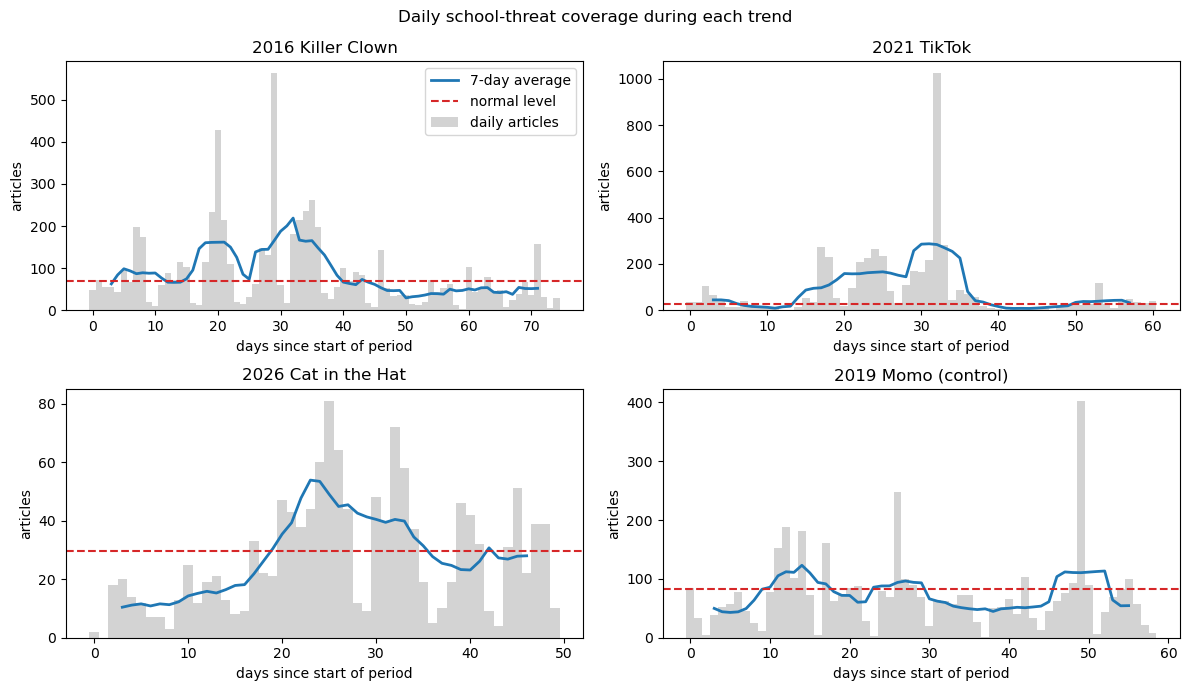

,case,peak 7-day avg,peak date,days to peak,peak / normal,busiest day,busiest day % of period
0,2016 Killer Clown,218.9,2016-10-03,32,3.1,2016-09-30,8.8
1,2021 TikTok,287.0,2021-12-16,31,10.1,2021-12-17,20.5
2,2026 Cat in the Hat,53.9,2026-08-24,23,1.8,2026-08-26,6.0
3,2019 Momo (control),123.1,2019-02-15,14,1.5,2019-03-22,9.5


In [3]:
WINDOW = 7

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
summary = []

for ax, (name, df) in zip(axes.flat, daily.items()):
    smooth = df["articles"].rolling(WINDOW, center=True).mean()
    days_in = (df["day"] - df["day"].min()).dt.days

    ax.bar(days_in, df["articles"], color="lightgray", width=1, label="daily articles")
    ax.plot(days_in, smooth, color="tab:blue", linewidth=2, label="7-day average")
    ax.axhline(normal[name], color="tab:red", linestyle="--", label="normal level")

    ax.set_title(name)
    ax.set_xlabel("days since start of period")
    ax.set_ylabel("articles")

    peak_pos = smooth.idxmax()
    busiest = df["articles"].idxmax()
    summary.append({
        "case": name,
        "peak 7-day avg": round(smooth.max(), 1),
        "peak date": df.loc[peak_pos, "day"].date(),
        "days to peak": int(days_in[peak_pos]),
        "peak / normal": round(smooth.max() / normal[name], 1),
        "busiest day": df.loc[busiest, "day"].date(),
        "busiest day % of period": round(df.loc[busiest, "articles"] / df["articles"].sum() * 100, 1),
    })

axes.flat[0].legend(loc="upper right")
fig.suptitle("Daily school-threat coverage during each trend")
fig.tight_layout()
fig.savefig(os.path.join(FIGURES, "q3_trend_shapes.png"), dpi=200)
plt.show()

shapes = pd.DataFrame(summary)
shapes

**What we see**

- **2021 TikTok is the strongest trend by far.** It reached about 10 times its normal level. Coverage built for two weeks, and a single day, December 17, holds one fifth of all the articles in the period. It then dropped below normal right as winter break began.
- **2016 Killer Clown reached 3.1 times normal** and came in two separate peaks, about two weeks apart, rather than one.
- **2026 Cat in the Hat is the weakest trend, at 1.8 times normal.** It rose slowly with the return to school and has no single dominant day.
- **Momo reached only 1.5 times its normal level** and has no clear wave, only scattered rises. Its busiest day, March 22, sits well after its highest week.

**Answer to Question 3.** The three trends do not share one shape. 2021 was a sudden spike around one date, 2016 was a longer run with two peaks, and 2026 was a slow and modest rise.

## Block 4: How long each wave lasted (Question 4)

**This block answers Question 4.** We want to know whether each new trend keeps the news busy for longer than the last one.

A wave is measured as the longest run of consecutive days in which the 7-day average stayed above the case's normal level. Extra articles counts how much coverage the wave added beyond an ordinary stretch of the same length, so it combines how long and how big the wave was.

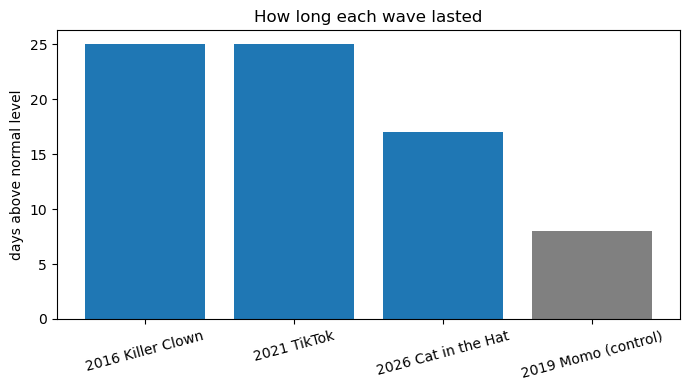

,case,wave start,wave end,days above normal,extra articles
0,2016 Killer Clown,2016-09-16,2016-10-10,25,1740
1,2021 TikTok,2021-11-29,2021-12-23,25,3352
2,2026 Cat in the Hat,2026-08-20,2026-09-05,17,235
3,2019 Momo (control),2019-02-11,2019-02-18,8,275


In [4]:
def longest_wave(df, level):
    """Return the rows of the longest stretch where the 7-day average is above level."""
    smooth = df["articles"].rolling(WINDOW, center=True).mean()
    above = smooth > level

    # Every time the line crosses the level a new stretch begins, so a running count
    # of the crossings gives each stretch its own number.
    stretch = (above != above.shift()).cumsum()
    lengths = stretch[above].value_counts()
    if lengths.empty:
        return df.iloc[0:0]
    return df[stretch == lengths.idxmax()]


rows = []
for name, df in daily.items():
    wave = longest_wave(df, normal[name])
    rows.append({
        "case": name,
        "wave start": wave["day"].min().date(),
        "wave end": wave["day"].max().date(),
        "days above normal": len(wave),
        "extra articles": int((wave["articles"] - normal[name]).sum()),
    })

durations = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
colors = ["tab:blue", "tab:blue", "tab:blue", "gray"]
ax.bar(durations["case"], durations["days above normal"], color=colors)
ax.set_ylabel("days above normal level")
ax.set_title("How long each wave lasted")
plt.xticks(rotation=15)
fig.tight_layout()
fig.savefig(os.path.join(FIGURES, "q4_wave_length.png"), dpi=200)
plt.show()

durations

**What we see**

- 2016 and 2021 each stayed above normal for 25 days.
- 2026 lasted 17 days, the shortest of the three trends, and added only about 230 extra articles.
- 2021 added the most coverage, about twice as much as 2016 in the same number of days.
- The 2021 wave ends on December 23, at the start of winter break, so the school calendar may have cut it short.
- The 2026 wave ends on September 5, two weeks before the data stops, so it was not cut off by the end of the period.

## Block 5: Check that the answer does not depend on the threshold

**This block handles the reliability check.** "Above normal" is a choice. If the answer to Question 4 changed completely with a slightly stricter line, it would not be a trustworthy result.

So the wave length is measured again with three lines: the normal level, 1.5 times normal and 2 times normal. If the order of the trends holds at every line, the answer is robust.

In [5]:
THRESHOLDS = [1.0, 1.5, 2.0]

robust = pd.DataFrame({
    f"{t}x normal": {
        name: len(longest_wave(df, normal[name] * t))
        for name, df in daily.items()
    }
    for t in THRESHOLDS
})
robust.index.name = "longest wave, in days"
robust

,1.0x normal,1.5x normal,2.0x normal
"longest wave, in days",,,
2016 Killer Clown,25,13,10
2021 TikTok,25,23,22
2026 Cat in the Hat,17,6,0
2019 Momo (control),8,0,0


**What we see**

- **2026 is the shortest trend at every line.** It never reaches twice its normal level at all.
- 2021 lasts as long as 2016 at the normal level and longer at the stricter lines: 23 days against 13 at 1.5 times normal, and 22 against 10 at twice normal.
- **Momo never rises above 1.5 times its normal level**, so under any stricter line it has no wave at all.

**Answer to Question 4.** The trends are not getting longer over time. 2021 was longer and stronger than 2016, but 2026 was the shortest and weakest of the three, under every definition tested. There is no steady increase from one trend to the next.

## Block 6: What each wave was made of (Question 5)

**This block answers Question 5.** The Momo panic involved no threats against schools, so if the measurement worked perfectly, Momo would barely register. Blocks 3 to 5 already show its rise was small. This block asks a second question: when Momo did rise, what kind of coverage was it?

The BigQuery export sorted every article into a keyword category based on its web address. Only the days inside each wave from Block 4 are counted, so the shares describe the wave itself and not the quiet days around it.

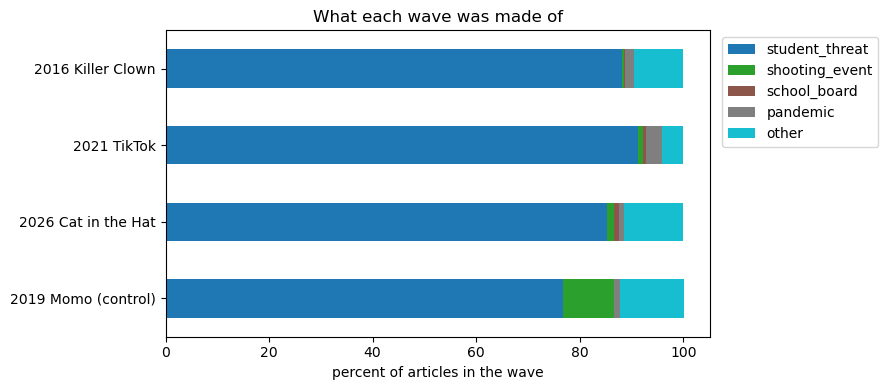

category,student_threat,shooting_event,school_board,pandemic,other
2016 Killer Clown,88.1,0.5,0.1,1.7,9.6
2021 TikTok,91.3,0.9,0.6,3.0,4.2
2026 Cat in the Hat,85.3,1.4,0.8,1.1,11.4
2019 Momo (control),76.8,9.8,0.1,1.0,12.4


In [6]:
CATEGORY_FILES = {
    "2016 Killer Clown": "03_daily_categories_2016_clowns.csv",
    "2021 TikTok": "05_daily_categories_2021_tiktok.csv",
    "2026 Cat in the Hat": "06_daily_categories_2026_cathat.csv",
    "2019 Momo (control)": "16_daily_categories_2019_momo.csv",
}
CATEGORY_ORDER = ["student_threat", "shooting_event", "school_board", "pandemic", "other"]

shares = {}
for name, filename in CATEGORY_FILES.items():
    cats = pd.read_csv(os.path.join(FOLDER, filename))
    cats["day"] = pd.to_datetime(cats["day"].astype(str), format="%Y%m%d")

    wave = longest_wave(daily[name], normal[name])
    in_wave = cats[cats["day"].between(wave["day"].min(), wave["day"].max())]

    totals = in_wave.groupby("category")["articles"].sum()
    shares[name] = totals / totals.sum() * 100

shares = pd.DataFrame(shares).T.reindex(columns=CATEGORY_ORDER).fillna(0).round(1)

ax = shares.plot(kind="barh", stacked=True, figsize=(9, 4), colormap="tab10")
ax.set_xlabel("percent of articles in the wave")
ax.set_title("What each wave was made of")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "q5_wave_categories.png"), dpi=200)
plt.show()

shares

**What we see**

- In the three real trends, between 85 and 91 percent of the articles fall in the `student_threat` category.
- In the Momo control, which involved no actual threats, **77 percent still fall in `student_threat`**.
- Momo has more `shooting_event` coverage than any trend, about 10 percent.

**Answer to Question 5.** Measured by size and length, the control stays quiet: Momo never passed 1.5 times its normal level and its longest rise lasted 8 days. But the keyword categories cannot tell it apart from a real trend, since they sort most of its articles as student threats. Keywords alone are not enough to decide what an article is about, which is the reason the project trains a classifier on the article text.

## Summary

This notebook compares three viral school-threat trends and one control using only the number of articles published each day, each measured against the same weeks of the year in ordinary years.

| Case | Normal level (articles per day) | Peak / normal | Longest wave (days) | Extra articles | Student threat share in wave |
|---|---|---|---|---|---|
| 2016 Killer Clown | 70.0 | 3.1 | 25 | 1,740 | 88% |
| 2021 TikTok | 28.5 | 10.1 | 25 | 3,352 | 91% |
| 2026 Cat in the Hat | 29.5 | 1.8 | 17 | 235 | 85% |
| 2019 Momo (control) | 83.0 | 1.5 | 8 | 275 | 77% |

- **Question 3.** Each trend had a different shape. 2021 was a sharp spike concentrated on December 17, 2016 came in two peaks, and 2026 was a slow, modest rise.
- **Question 4.** The trends are not lasting longer over time. 2026 was the shortest trend under every threshold tested.
- **Question 5.** The Momo control produced only a small, short rise, but keyword rules still sorted most of its coverage as student threats, which shows why a text classifier is needed.

**Limitations**

- Articles are found by words in their web address, not in their text, so some coverage is missed and some unrelated coverage gets in.
- The comparison years contain real threat waves of their own. The median limits their effect, but it does not remove it.
- The 2021 wave may have been cut short by winter break.
- With three trends, the answer to Question 4 describes these cases. It is not a statistical test of a long-term pattern.